In [5]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

cst = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_CST_FaMap.tsv'), sep = '\t')
cst = cst[cst.regionname == 'CST_R']

# MADS cerebellum (4 regions per hemisphere)
cerebel = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_Nettekoven_MADS_FaMap.tsv'), sep = '\t')
cerebel = cerebel[cerebel.hemisphere == 'L']

# behavioural metrics
behav = pd.read_csv(os.path.join(gl.baseDir, 'behavioural', 'summary_paretic.dat'), sep = '\t')
behav.rename(columns = {'subj_name': 'subj_id', 'week': 'Week'}, inplace = True)
behav['subj_id'] = behav['subj_id'].str.strip()
behav.loc[behav['Week']==1, 'Week'] = 0

week 0: r = -0.41581001002915907, p-value = 0.07662454659549506
week 4: r = -0.5243617066609374, p-value = 0.010212488401406114
week 12: r = -0.4663696306444708, p-value = 0.018775974113142573
week 24: r = -0.6420319728068966, p-value = 0.0012759755192137381
week 52: r = -0.15993995180125348, p-value = 0.6589447402439906


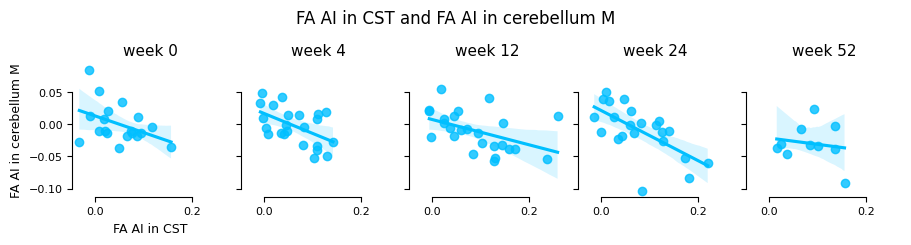

week 0: r = -0.13083232615447388, p-value = 0.593429526062033
week 4: r = -0.5840062550276796, p-value = 0.0034346267890306556
week 12: r = -0.5520285034210711, p-value = 0.004222839107971542
week 24: r = -0.6109940990528224, p-value = 0.002521974039328815
week 52: r = -0.34263955020959297, p-value = 0.33244626186440396


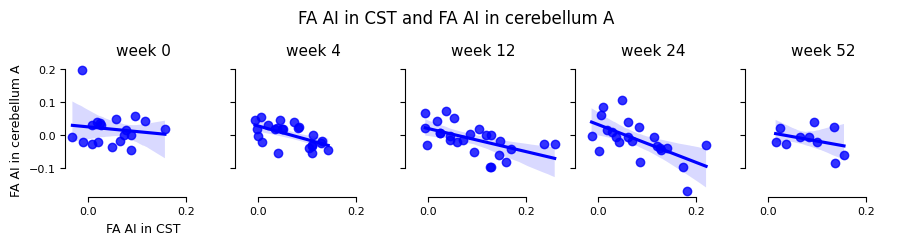

week 0: r = -0.15055863093870336, p-value = 0.5383964342787654
week 4: r = -0.6064633880087253, p-value = 0.0021560382294991054
week 12: r = -0.4765556476862595, p-value = 0.01602190025167977
week 24: r = -0.5499108298157671, p-value = 0.008016082433966974
week 52: r = -0.012449835108411772, p-value = 0.9727702065362785


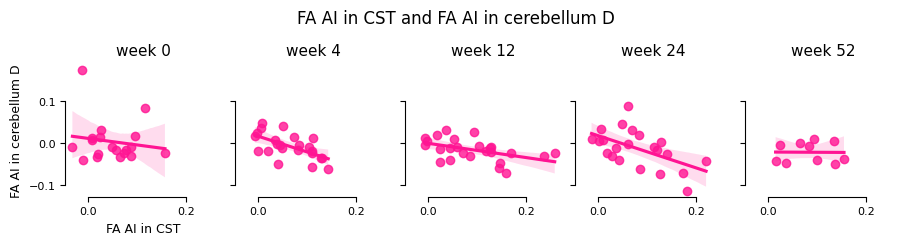

week 0: r = -0.1255765474803959, p-value = 0.6084758719470678
week 4: r = -0.2002882713324841, p-value = 0.359501409033668
week 12: r = 0.1285889845819086, p-value = 0.5401538698159112
week 24: r = -0.2504390450915324, p-value = 0.2609592585308584
week 52: r = 0.11373546532862318, p-value = 0.7543971359512786


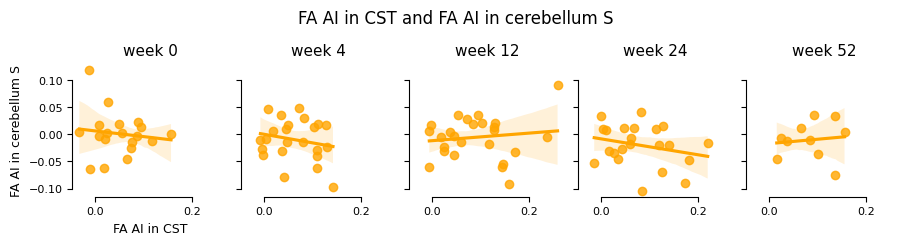

In [11]:
colours = ['deepskyblue', 'blue', 'deeppink', 'orange']
for r,roi in enumerate(['M', 'A', 'D', 'S']):
    fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
    for i, week in enumerate(gl.weeks):
        cerebel_plot = cerebel[(cerebel.Week == week)&(cerebel.regionname.str[0]==roi)]
        cst_plot = cst[cst.Week == week]
        cerebel_cst_plot = pd.merge(cst_plot, cerebel_plot, on = ['subj_id', 'Week'], how = 'inner', suffixes = ('_cst', '_cerebel_plot'))

        r_stat, p_stat = stats.pearsonr(cerebel_cst_plot['asymmetry_index_cerebel_plot'],cerebel_cst_plot['asymmetry_index_cst'])
        print(f'week {week}: r = {r_stat}, p-value = {p_stat}')

        ax = axs[i]
        sns.regplot(x = 'asymmetry_index_cst', y = 'asymmetry_index_cerebel_plot', data = cerebel_cst_plot, ax = ax, 
                    color = colours[r]) # see what happens when switch x, y
        ax.set_ylabel('')
        ax.set_xlabel('')

        ax.set_title(f'week {week}')

    axs[0].set_ylabel(f"FA AI in cerebellum {roi}")
    axs[0].set_xlabel(f"FA AI in CST")
    fig.suptitle(f"FA AI in CST and FA AI in cerebellum {roi}", y = 1.15)
    sns.despine(trim = True)
    plt.show()

week 0: r = 0.09226979526318409, p-value = 0.7246786020525945
week 4: r = 0.07529916857946714, p-value = 0.7391028984302129
week 12: r = 0.30324950344485974, p-value = 0.14973083713766713
week 24: r = 0.2167821026265796, p-value = 0.3452305845777402
week 52: r = 0.5088736614418218, p-value = 0.1330692445969478


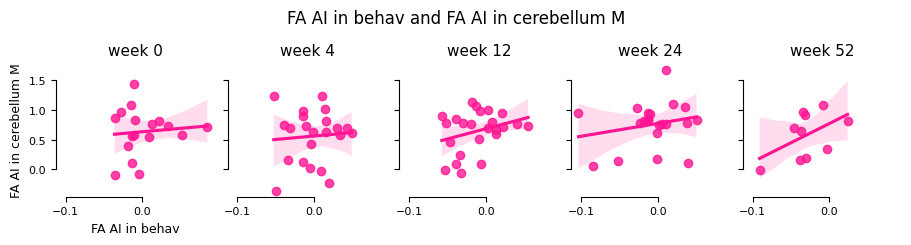

week 0: r = -0.1710261523821493, p-value = 0.5116248133462883
week 4: r = 0.2547616537218589, p-value = 0.2525440688628265
week 12: r = -0.07112606636116917, p-value = 0.7412016508379841
week 24: r = 0.14468318717351344, p-value = 0.5314926953584428
week 52: r = 0.36665485620527094, p-value = 0.29734877786265074


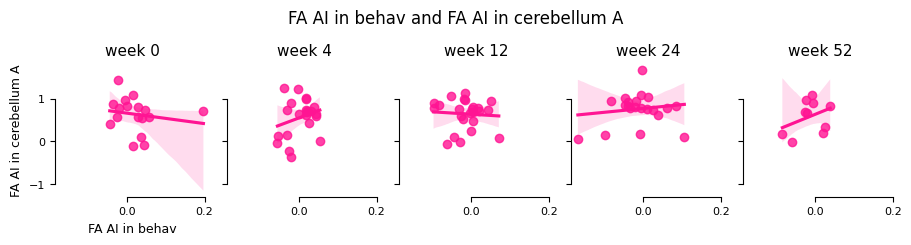

week 0: r = -0.20635841329587448, p-value = 0.4268237664093285
week 4: r = 0.3533875887559795, p-value = 0.10667212266221879
week 12: r = 0.13748793417771438, p-value = 0.5217516801847891
week 24: r = 0.2114531508005585, p-value = 0.3575049763911914
week 52: r = 0.24352728695739706, p-value = 0.4977687557370942


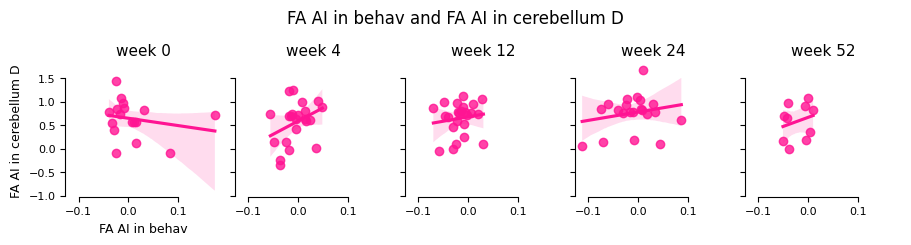

week 0: r = 0.03796813483142625, p-value = 0.8849685298786556
week 4: r = 0.34920479599786647, p-value = 0.11117692898915044
week 12: r = 0.16731802137706056, p-value = 0.4345305255712352
week 24: r = -0.0057949495770781324, p-value = 0.9801109778688675
week 52: r = 0.13770233381813707, p-value = 0.7044232407341823


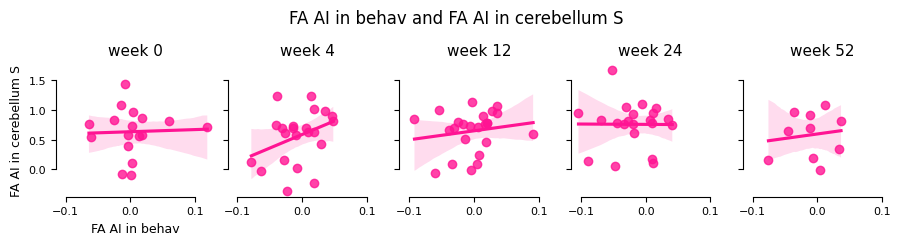

In [12]:
colours = ['deepskyblue', 'blue', 'deeppink', 'orange']
for r,roi in enumerate(['M', 'A', 'D', 'S']):

    fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
    for i, week in enumerate(gl.weeks):
        cerebel_plot = cerebel[(cerebel.Week == week)&(cerebel.regionname.str[0]==roi)]
        behav_plot = behav[behav.Week == week]
        cerebel_behav_plot = pd.merge(behav_plot, cerebel_plot, on = ['subj_id', 'Week'], how = 'inner', suffixes = ('_behav', '_cerebel'))

        r_stat, p_stat = stats.pearsonr(cerebel_behav_plot['asymmetry_index'],cerebel_behav_plot['indiv_norm'])
        print(f'week {week}: r = {r_stat}, p-value = {p_stat}')

        ax = axs[i]
        sns.regplot(y = 'indiv_norm', x = 'asymmetry_index', data = cerebel_behav_plot, ax = ax, color = 'deeppink') # see what happens when switch x, y
        ax.set_ylabel('')
        ax.set_xlabel('')

        ax.set_title(f'week {week}')

    axs[0].set_ylabel(f"FA AI in cerebellum {roi}")
    axs[0].set_xlabel(f"FA AI in behav")
    fig.suptitle(f"FA AI in behav and FA AI in cerebellum {roi}", y = 1.15)
    sns.despine(trim = True)
    plt.show()

week 0: r = 0.253426981897355, p-value = 0.326364207868902
week 4: r = 0.07175834756433959, p-value = 0.750986264999895
week 12: r = 0.31058204155942937, p-value = 0.13964232455868603
week 24: r = 0.17037174692680526, p-value = 0.4602966093827816
week 52: r = 0.37747225390607303, p-value = 0.28221541848771076


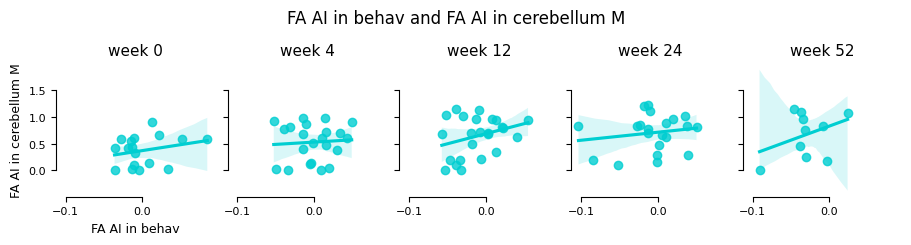

week 0: r = -0.050909085532095104, p-value = 0.8461445388631551
week 4: r = 0.2690537367033263, p-value = 0.22597469671132642
week 12: r = -0.06344610615972696, p-value = 0.7683566782749701
week 24: r = 0.11651472597720204, p-value = 0.6149912225739217
week 52: r = 0.17213730593557722, p-value = 0.6344103320836375


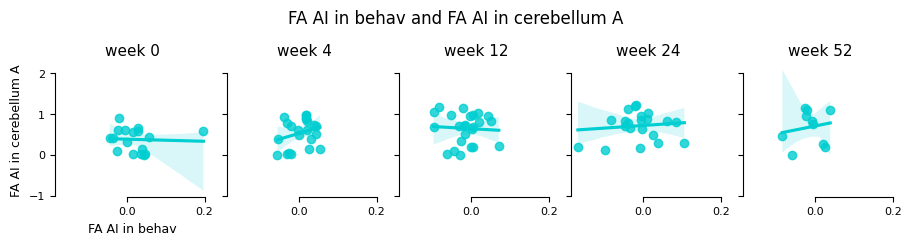

week 0: r = 0.005297569201799284, p-value = 0.9839008474938249
week 4: r = 0.3507286208847351, p-value = 0.10952004278499929
week 12: r = 0.12308824239767371, p-value = 0.5666431898276254
week 24: r = 0.026836720700124404, p-value = 0.9080717801849605
week 52: r = -0.130922621940273, p-value = 0.7184654742989162


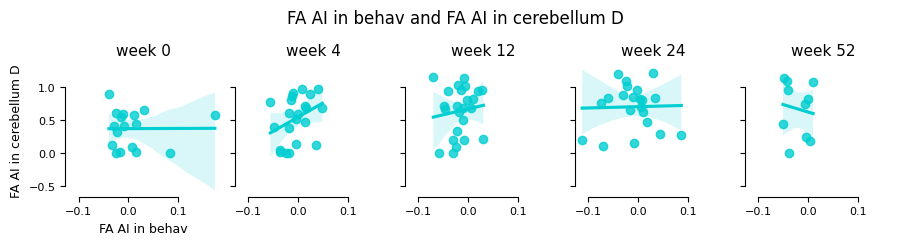

week 0: r = 0.10603850565872384, p-value = 0.6854398678581531
week 4: r = 0.25422811808496226, p-value = 0.2535731930304103
week 12: r = -0.06660025748462818, p-value = 0.7571701285096084
week 24: r = 0.06888163780415175, p-value = 0.766711498395532
week 52: r = -0.13945178934070868, p-value = 0.7008125753553083


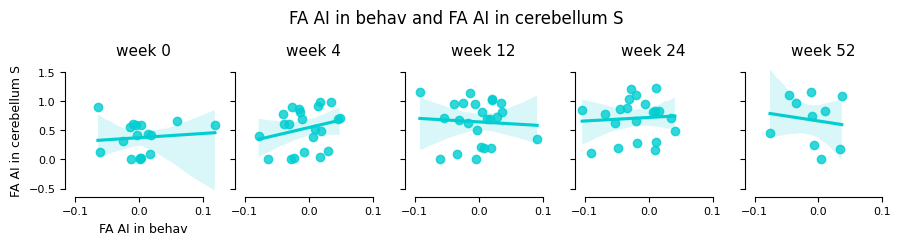

In [13]:
colours = ['deepskyblue', 'blue', 'deeppink', 'orange']
for r,roi in enumerate(['M', 'A', 'D', 'S']):

    fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
    for i, week in enumerate(gl.weeks):
        cerebel_plot = cerebel[(cerebel.Week == week)&(cerebel.regionname.str[0]==roi)]
        behav_plot = behav[behav.Week == week]
        cerebel_behav_plot = pd.merge(behav_plot, cerebel_plot, on = ['subj_id', 'Week'], how = 'inner', suffixes = ('_behav', '_cerebel'))

        r_stat, p_stat = stats.pearsonr(cerebel_behav_plot['asymmetry_index'],cerebel_behav_plot['mvc_norm'])
        print(f'week {week}: r = {r_stat}, p-value = {p_stat}')

        ax = axs[i]
        sns.regplot(y = 'mvc_norm', x = 'asymmetry_index', data = cerebel_behav_plot, ax = ax, color = 'darkturquoise') # see what happens when switch x, y
        ax.set_ylabel('')
        ax.set_xlabel('')

        ax.set_title(f'week {week}')

    axs[0].set_ylabel(f"FA AI in cerebellum {roi}")
    axs[0].set_xlabel(f"FA AI in behav")
    fig.suptitle(f"FA AI in behav and FA AI in cerebellum {roi}", y = 1.15)
    sns.despine(trim = True)
    plt.show()

In [18]:
# FISHER Z TRANSFORM - INDIVIDUATION
rows_indiv = []
for roi in ['M', 'A', 'D', 'S']:
    for week in gl.weeks:
        cerebel_week_plot = cerebel[(cerebel.Week == week)&(cerebel.regionname.str[0] == roi)]
        cerebel_plot = cerebel_week_plot.groupby(['subj_id'], as_index = False)['asymmetry_index'].mean()
        behav_plot = behav[(behav.Week == week)].groupby('subj_id', as_index = False)['indiv_norm'].mean()
        behav_cerebel = pd.merge(behav_plot, cerebel_plot, on = ['subj_id'], how = 'inner', suffixes = ('_behav', '_cerebel'))
        
        r_stat, p_val = stats.pearsonr(behav_cerebel['asymmetry_index'], behav_cerebel['indiv_norm']) # use fitted value from piecewise function, y_hat

        n = len(behav_cerebel.subj_id.unique())
        z, se = np.arctanh(r_stat), 1/np.sqrt(n-3)
        lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
        rows_indiv.append({'regionname': roi, 'Week': week, 'r_stat': r_stat, 'p_val': p_val, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
rdf_indiv = pd.DataFrame(rows_indiv)

In [19]:
# FISHER Z TRANSFORM - STRENGTH
rows_mvc = []
for roi in ['M', 'A', 'D', 'S']:
    for week in gl.weeks:
        cerebel_week_plot = cerebel[(cerebel.Week == week)&(cerebel.regionname.str[0] == roi)]
        cerebel_plot = cerebel_week_plot.groupby(['subj_id'], as_index = False)['asymmetry_index'].mean()
        behav_plot = behav[(behav.Week == week)].groupby('subj_id', as_index = False)['mvc_norm'].mean()
        behav_cerebel = pd.merge(behav_plot, cerebel_plot, on = ['subj_id'], how = 'inner', suffixes = ('_behav', '_cerebel'))
        
        r_stat, p_val = stats.pearsonr(behav_cerebel['asymmetry_index'], behav_cerebel['mvc_norm']) # use fitted value from piecewise function, y_hat

        n = len(behav_cerebel.subj_id.unique())
        z, se = np.arctanh(r_stat), 1/np.sqrt(n-3)
        lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
        rows_mvc.append({'regionname': roi, 'Week': week, 'r_stat': r_stat, 'p_val': p_val, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
rdf_mvc = pd.DataFrame(rows_mvc)

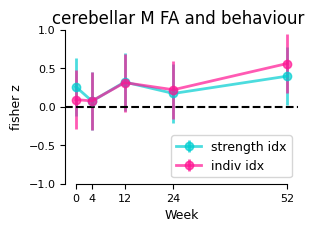

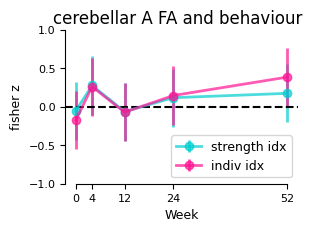

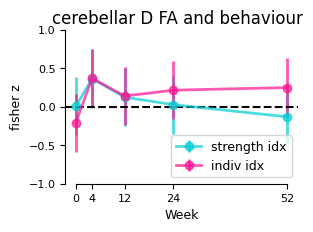

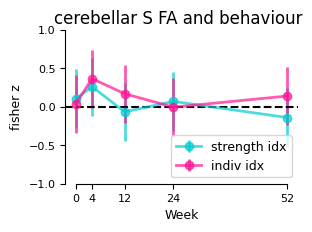

In [22]:
colours = ['deepskyblue', 'blue', 'deeppink', 'orange']
for r,roi in enumerate(['M', 'A', 'D', 'S']):
    fig, ax = plt.subplots(figsize = (3,2))

    # strength
    
    ax.errorbar(x = rdf_mvc[rdf_mvc.regionname == roi]['Week'], y = rdf_mvc[rdf_mvc.regionname == roi]['z'], yerr = se,              
    marker = 'o', linestyle = '-', linewidth = 2, color = 'darkturquoise', alpha = .7, label = 'strength idx')

    # individuation
    ax.errorbar(x = rdf_indiv[rdf_indiv.regionname == roi]['Week'], y = rdf_indiv[rdf_indiv.regionname == roi]['z'], yerr = se,              
    marker = 'o', linestyle = '-', linewidth = 2, color = 'deeppink', alpha = .7, label = 'indiv idx')


    ax.set_xticks(gl.weeks)
    ax.set_xlabel('Week')
    ax.set_ylabel('fisher z')
    plt.legend(loc = 'lower right')
    plt.suptitle(f"cerebellar {roi} FA and behaviour")
    ax.set_ylim(-1, 1)
    plt.axhline(y = 0, linestyle = '--', color = 'k', linewidth = '1.5')
    sns.despine(trim = True)
    plt.show()